# Lab 05: Predict late deliveries

This notebook reads the results that `python -m latedeliveries.train` saved in `reports/`.
It does not score the test set again: the test set was used once, inside `train.py`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score

from latedeliveries.data import make_orders
from latedeliveries.pipeline import CATEGORICAL, NUMERIC, build_pipeline, split_orders
from latedeliveries.train import make_folds

ROOT = Path("..")
REPORTS = ROOT / "reports"
orders = make_orders()

## 1. How common are late orders?

(3000, 11)
Late rate: 0.156
prep_minutes        189
customer_rating    1489
dtype: int64


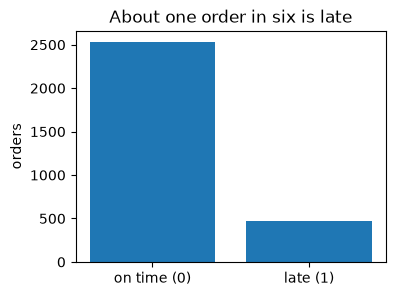

In [2]:
print(orders.shape)
print(f"Late rate: {orders['late'].mean():.3f}")
print(orders.isna().sum()[orders.isna().sum() > 0])

counts = orders["late"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(["on time (0)", "late (1)"], counts.values)
ax.set_ylabel("orders")
ax.set_title("About one order in six is late")
plt.show()

## 2. Model comparison (5-fold CV, training data only)

In [3]:
cv_results = pd.read_csv(REPORTS / "cv_results.csv")
cv_results

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,best_threshold,cv_cost
0,dummy,0.844,0.001,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000,0.05,5265
1,logistic,0.862,0.009,0.654,0.065,0.242,0.053,0.352,0.064,0.795,0.034,0.30,4031
2,logistic_balanced,0.737,0.019,0.333,0.027,0.681,0.049,0.447,0.034,0.795,0.034,0.70,4098
3,random_forest_balanced,0.785,0.016,0.378,0.030,0.587,0.060,0.459,0.038,0.783,0.025,0.60,4241
4,gradient_boosting,0.861,0.007,0.635,0.050,0.265,0.024,0.373,0.029,0.788,0.031,0.30,4152


## 3. Leakage check

`customer_rating` is given after the order arrives. Adding it back makes the score jump,
which is a warning, not good news. This uses the training rows only.

In [4]:
X_train, _, y_train, _ = split_orders(orders)
train_rows = orders.loc[X_train.index]  # same training rows, all columns


def cv_auc(numeric):
    pipe = build_pipeline(LogisticRegression(max_iter=1000), numeric, CATEGORICAL)
    scores = cross_val_score(
        pipe, train_rows, y_train, cv=make_folds(), scoring="roc_auc"
    )
    return round(scores.mean(), 3)


print("ROC-AUC, official features:   ", cv_auc(NUMERIC))
print("ROC-AUC, with customer_rating:", cv_auc(NUMERIC + ["customer_rating"]))

ROC-AUC, official features:    0.795


ROC-AUC, with customer_rating: 0.907


## 4. Cost against threshold (out-of-fold, training data)

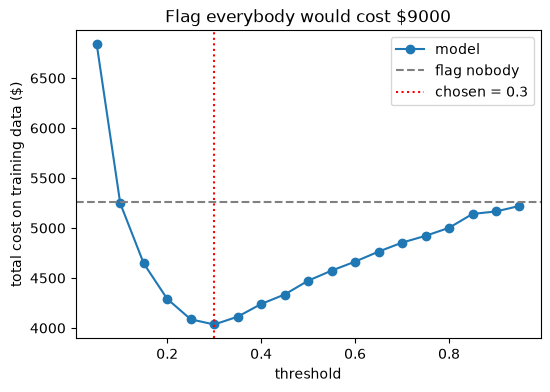

In [5]:
costs = pd.read_csv(REPORTS / "threshold_costs.csv")
metrics = json.loads((REPORTS / "metrics.json").read_text())
chosen = metrics["threshold"]
nobody = 15 * int(y_train.sum())
everybody = 4 * len(y_train)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(costs["threshold"], costs["cost"], marker="o", label="model")
ax.axhline(nobody, linestyle="--", color="grey", label="flag nobody")
ax.axvline(chosen, linestyle=":", color="red", label=f"chosen = {chosen}")
ax.set_xlabel("threshold")
ax.set_ylabel("total cost on training data ($)")
ax.set_title(f"Flag everybody would cost ${everybody}")
ax.legend()
plt.show()

## 5. Test set confusion matrix (scored once, in train.py)

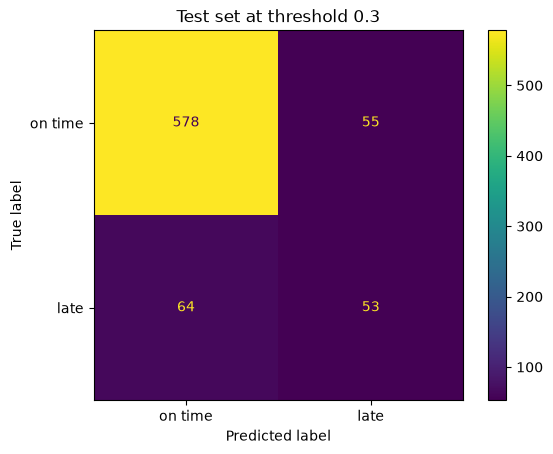

precision  0.491
recall     0.453
f1         0.471
roc_auc    0.796


In [6]:
cm = metrics["confusion_matrix"]
matrix = np.array([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]])
ConfusionMatrixDisplay(matrix, display_labels=["on time", "late"]).plot()
plt.title(f"Test set at threshold {chosen}")
plt.show()
for name in ("precision", "recall", "f1", "roc_auc"):
    print(f"{name:10s} {metrics[name]}")

## 6. Cost of the three policies on the test set

flag_nobody       1755
flag_everybody    3000
model             1392
dtype: int64
Saving against flagging nobody: $363 (21%)


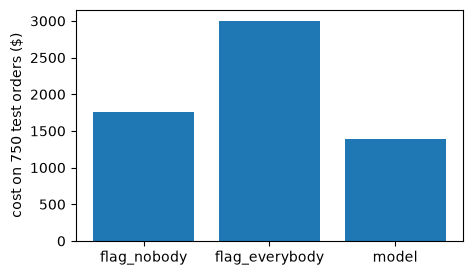

In [7]:
policy = pd.Series(metrics["costs"])
print(policy)
saving = policy["flag_nobody"] - policy["model"]
share = saving / policy["flag_nobody"]
print(f"Saving against flagging nobody: ${saving} ({share:.0%})")

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(policy.index, policy.values)
ax.set_ylabel("cost on 750 test orders ($)")
plt.show()

## Recommendation

**Would I use this model?** Yes. On 750 orders it never saw, it cost \$1,392 against \$1,755
for flagging nobody (today's policy) and \$3,000 for flagging everybody. That is a saving of
about 21%, close to the 23% it saved in cross-validation, so the gain looks real.

**Why this threshold?** A voucher costs \$4 and a missed late order costs \$15, so flagging pays
when the chance of being late is above about 4/15 = 0.27. The out-of-fold cost on the training
data was lowest at 0.30, which matches that break-even point.

**What did I exclude?** `customer_rating`, because it is given after delivery; adding it
back raises ROC-AUC from 0.795 to 0.907, which is leakage. `order_id`, because it is only a label.

**One limitation.** `prep_minutes` is the real kitchen time, which is not fully known when
the order is placed. In practice the model would need the restaurant's estimate instead,
and the saving should be checked again with that estimate.